# 02 — Feature Engineering & Labeling: C-MAPSS FD001

Builds on `01_eda.ipynb`'s output (`data/processed/fd001_sensor_selection.json`).
See `docs/project_brief.md` Sections 3 and 5, and the module docstrings in
`src/turbofan_rul/labeling.py` and `src/turbofan_rul/features.py` for the
full reasoning — this notebook is deliberately thin: almost everything here
is a call into the shared `src/` package, since that package (not this
notebook) is what the API imports later.

This notebook:
1. Loads FD001 + the Phase 1 sensor selection
2. Builds the row-level piecewise-linear RUL label and sanity-checks it visually
3. Builds the row-level feature matrix (rolling stats, trend slope, EWMA, cycle count)
4. Builds the **survival (duration, event) tables** — train (all `event=1`, at
   the capped remaining life) and test (all `event=0`, right-censored) — the
   object every survival model in Phase 3–5 will actually be fit on
5. Spot-checks that engine-level train/test splits weren't crossed anywhere
6. Saves everything to `data/processed/` for the modeling notebooks


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, features, labeling, plotting

plotting.style()
SUBSET = "FD001"
CAP = 125
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load data + Phase 1 sensor selection

In [2]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)

kept_sensors = features.load_kept_sensors(PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json")
print(f"{len(kept_sensors)} kept sensors from Phase 1: {kept_sensors}")

12 kept sensors from Phase 1: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 2. Piecewise-linear RUL labels

Sanity check: for a sample engine, RUL should be **flat at the cap** for
most of its early life, then count down linearly to 0 at the last observed
cycle — not a straight line from cycle 1.

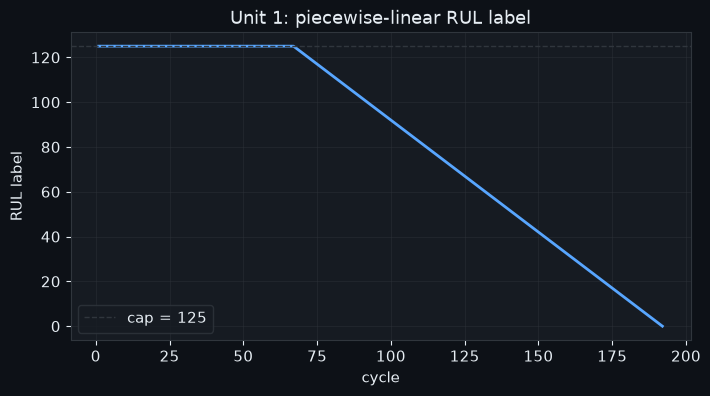

OK: RUL reaches 0 at final cycle for sample engine.


In [3]:
labeled_train = labeling.add_piecewise_rul(cmapss.train, cap=CAP)

sample_unit = 1
traj = labeled_train[labeled_train.unit_number == sample_unit]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(traj["time_cycles"], traj["RUL"], color=plotting.C0, linewidth=2)
ax.axhline(CAP, color=plotting.GRID, linestyle="--", linewidth=1, label=f"cap = {CAP}")
ax.set_xlabel("cycle")
ax.set_ylabel("RUL label")
ax.set_title(f"Unit {sample_unit}: piecewise-linear RUL label")
ax.legend()
plt.show()

assert traj["RUL"].iloc[-1] == 0, "RUL should hit exactly 0 at an engine's final observed cycle"
print("OK: RUL reaches 0 at final cycle for sample engine.")

## 3. Feature matrix

Rolling mean/std/min/max/slope (windows of 5/15/30 cycles) + EWMA (spans
10/30) + cycle count, computed **per engine** — verified below by checking
that no NaNs remain and that engine boundaries aren't crossed.

In [4]:
feature_matrix = features.build_feature_matrix(labeled_train, kept_sensors=kept_sensors)

engineered_cols = [c for c in feature_matrix.columns if c not in labeled_train.columns]
print(f"{len(engineered_cols)} engineered feature columns added.")
print(f"Any NaNs in engineered features: {feature_matrix[engineered_cols].isna().sum().sum()}")

feature_matrix[["unit_number", "time_cycles", "RUL"] + engineered_cols[:6]].head()

205 engineered feature columns added.
Any NaNs in engineered features: 0


,unit_number,time_cycles,RUL,cycle_count,sensor_2_roll5_mean,sensor_2_roll5_std,sensor_2_roll5_min,sensor_2_roll5_max,sensor_2_roll5_slope
0,1,1,125,1,641.820000,0.000000,641.82,641.82,0.000
1,1,2,125,2,641.985000,0.233345,641.82,642.15,0.330
2,1,3,125,3,642.106667,0.267644,641.82,642.35,0.265
3,1,4,125,4,642.167500,0.250117,641.82,642.35,0.179
4,1,5,125,5,642.208000,0.234776,641.82,642.37,0.130


In [5]:
# Spot-check: an engine's rolling-window features shouldn't be influenced by
# the *previous* engine's trailing cycles. Compare the first row of engine 2's
# rolling mean to engine 2's own raw value at that row -- they should match
# exactly, since with min_periods=1 the first row of any window has exactly
# one observation available: itself.
sample_sensor = kept_sensors[0]
engine2_first_row = feature_matrix[feature_matrix.unit_number == 2].iloc[0]
assert np.isclose(engine2_first_row[f"{sample_sensor}_roll5_mean"], engine2_first_row[sample_sensor]), (
    "Engine 2's first-row rolling mean should equal its own raw sensor value -- "
    "if it doesn't, engine 1's trailing rows are leaking across the group boundary."
)
print("OK: no cross-engine leakage detected in rolling features (spot check).")

OK: no cross-engine leakage detected in rolling features (spot check).


## 4. Survival (duration, event) tables

This is the object the survival models in Phase 3–5 are actually fit on —
not the raw feature matrix directly.

**Train:** every training engine runs to failure, so each row's true
remaining life is known exactly. Every row gets `event=1` and
`duration` = its remaining life **capped at 125** — the same piecewise-linear
convention as the label in Section 2. For rows with more than 125 cycles
left, this deliberately records them as "125", the standard C-MAPSS
convention: remaining life beyond the cap isn't distinguished, which matches
how the task is evaluated.

Strictly, those rows are right-censored ("survived at least 125"), and
`labeling.build_train_survival_frame(..., censor_above_cap=True)` encodes them
that way. That was tested and rejected: Weibull AFT then extrapolates
remaining life far past the range of the official test set, and its NASA
score and interval width blow up (see the `labeling.py` docstring for the
numbers).

**Test:** one row per engine, taken at the engine's last observed cycle,
right-censored (`event=0`) — `true_rul` is carried along for evaluation only
and is never a model input.

In [6]:
train_survival = labeling.build_train_survival_frame(cmapss.train, cap=CAP)
train_survival = features.build_feature_matrix(train_survival, kept_sensors=kept_sensors)

test_labeled = features.build_feature_matrix(cmapss.test, kept_sensors=kept_sensors)
test_survival = labeling.build_test_survival_frame(test_labeled, cmapss.rul)

print(f"train_survival: {train_survival.shape}, event value counts:")
print(train_survival["event"].value_counts())
print(f"\ntest_survival: {test_survival.shape}, event value counts:")
print(test_survival["event"].value_counts())

assert (train_survival["event"] == 1).all()
assert train_survival["duration"].max() == CAP
assert (test_survival["event"] == 0).all()
assert len(test_survival) == cmapss.test["unit_number"].nunique()

n_at_cap = int((train_survival["duration"] == CAP).sum())
print(f"\nOK: every training row event=1 ({n_at_cap} / {len(train_survival)} rows sit at the "
      f"{CAP}-cycle cap); test fully censored, one row per engine.")

train_survival: (20631, 234), event value counts:
event
1    20631
Name: count, dtype: int64

test_survival: (100, 234), event value counts:
event
0    100
Name: count, dtype: int64

OK: every training row event=1 (8131 / 20631 rows sit at the 125-cycle cap); test fully censored, one row per engine.


## 5. Save processed tables for the modeling notebooks

In [7]:
feature_matrix.to_parquet(PROCESSED_DIR / f"{SUBSET.lower()}_train_features.parquet")
train_survival.to_parquet(PROCESSED_DIR / f"{SUBSET.lower()}_train_survival.parquet")
test_survival.to_parquet(PROCESSED_DIR / f"{SUBSET.lower()}_test_survival.parquet")

print("Saved:")
for f in sorted(PROCESSED_DIR.glob(f"{SUBSET.lower()}_*")):
    print(" ", f.name)

Saved:
  fd001_sensor_selection.json
  fd001_test_survival.parquet
  fd001_train_features.parquet
  fd001_train_survival.parquet
